# Comparative Customer Analysis

## Project Goal

This notebook builds on the exploratory data analysis by comparing customer characteristics and campaign outcomes across multiple variables.

Rather than examining variables independently, this analysis investigates how customer demographics, financial characteristics, and campaign interactions relate to term deposit subscription behavior.

These comparisons provide more meaningful business insights by identifying customer segments and campaign characteristics associated with higher or lower subscription rates.

In [1]:
# Import libraries
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import PercentFormatter
from matplotlib.ticker import StrMethodFormatter

# Load the dataset
df = pd.read_csv("../data/raw/bank-full.csv", sep=";")

# Display the first five rows
df.head()


,age,job,marital,education,default,balance,housing,loan,contact,day,month,duration,campaign,pdays,previous,poutcome,y
0,58,management,married,tertiary,no,2143,yes,no,unknown,5,may,261,1,-1,0,unknown,no
1,44,technician,single,secondary,no,29,yes,no,unknown,5,may,151,1,-1,0,unknown,no
2,33,entrepreneur,married,secondary,no,2,yes,yes,unknown,5,may,76,1,-1,0,unknown,no
3,47,blue-collar,married,unknown,no,1506,yes,no,unknown,5,may,92,1,-1,0,unknown,no
4,33,unknown,single,unknown,no,1,no,no,unknown,5,may,198,1,-1,0,unknown,no


## 1. Dataset Overview

Before comparing customer groups, verify the size and structure of the dataset.

In [2]:
print(f"Rows: {df.shape[0]:,}")
print(f"Columns: {df.shape[1]}")

df.info()

Rows: 45,211
Columns: 17
<class 'pandas.DataFrame'>
RangeIndex: 45211 entries, 0 to 45210
Data columns (total 17 columns):
 #   Column     Non-Null Count  Dtype
---  ------     --------------  -----
 0   age        45211 non-null  int64
 1   job        45211 non-null  str  
 2   marital    45211 non-null  str  
 3   education  45211 non-null  str  
 4   default    45211 non-null  str  
 5   balance    45211 non-null  int64
 6   housing    45211 non-null  str  
 7   loan       45211 non-null  str  
 8   contact    45211 non-null  str  
 9   day        45211 non-null  int64
 10  month      45211 non-null  str  
 11  duration   45211 non-null  int64
 12  campaign   45211 non-null  int64
 13  pdays      45211 non-null  int64
 14  previous   45211 non-null  int64
 15  poutcome   45211 non-null  str  
 16  y          45211 non-null  str  
dtypes: int64(7), str(10)
memory usage: 5.9 MB


## 2. Overall Campaign Outcome

The target variable `y` indicates whether a customer subscribed to a term deposit after the marketing campaign.

Understanding the overall subscription rate provides a baseline for evaluating individual customer segments.

In [3]:
subscription_counts = df["y"].value_counts()
subscription_rates = df["y"].value_counts(normalize=True) * 100

print("Subscription Counts:")
print(subscription_counts)

print("\nSubscription Rates:")
print(subscription_rates.round(2))

Subscription Counts:
y
no     39922
yes     5289
Name: count, dtype: int64

Subscription Rates:
y
no     88.3
yes    11.7
Name: proportion, dtype: float64


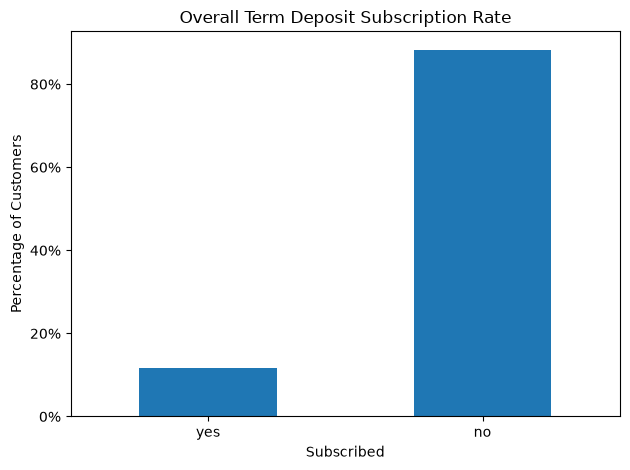

In [4]:
subscription_rates.sort_values().plot(kind="bar")

plt.title("Overall Term Deposit Subscription Rate")
plt.xlabel("Subscribed")
plt.ylabel("Percentage of Customers")
plt.gca().yaxis.set_major_formatter(PercentFormatter())
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

### Business Interpretation

The overall subscription rate establishes the baseline campaign response rate. Because substantially more customers did not subscribe than subscribed, the target variable is imbalanced.

This is important for later predictive modeling because accuracy alone may not provide an adequate measure of model performance. Metrics such as precision, recall, F1-score, and ROC-AUC should also be considered.

## 3. Subscription Rate by Job

Customer occupation may help identify segments that respond differently to marketing campaigns.

In [5]:
job_subscription = (
    df.groupby("job")["y"]
    .apply(lambda x: (x == "yes").mean() * 100)
    .sort_values(ascending=False)
)

job_subscription

job
student          28.678038
retired          22.791519
unemployed       15.502686
management       13.755551
admin.           12.202669
self-employed    11.842939
unknown          11.805556
technician       11.056996
services          8.883004
housemaid         8.790323
entrepreneur      8.271688
blue-collar       7.274969
Name: y, dtype: float64

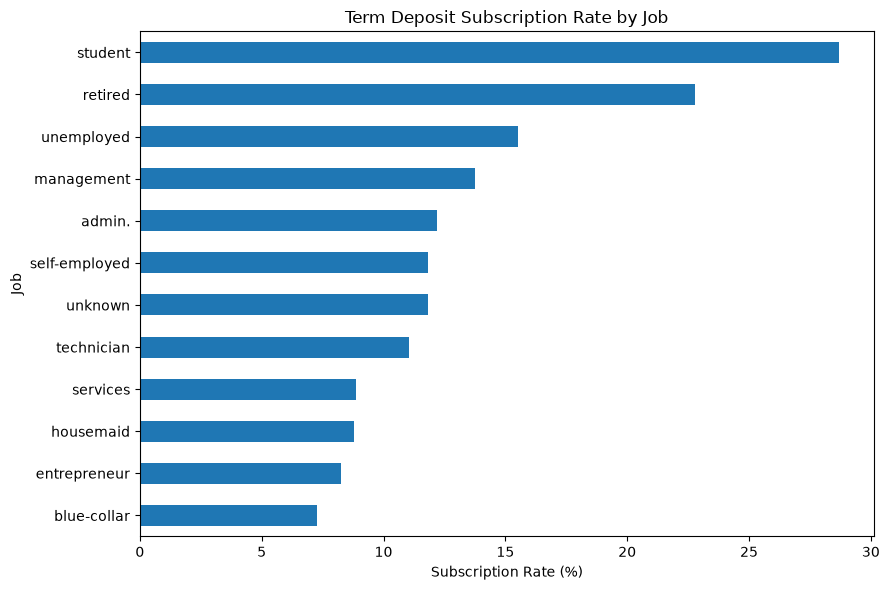

In [6]:
job_subscription.sort_values().plot(kind="barh", figsize=(9, 6))

plt.title("Term Deposit Subscription Rate by Job")
plt.xlabel("Subscription Rate (%)")
plt.ylabel("Job")
plt.tight_layout()
plt.show()

### Business Interpretation

Subscription rates vary across occupational groups, suggesting that customer occupation may contain useful information for customer segmentation.

However, response rate alone should not determine campaign targeting. Segment size, customer financial characteristics, and other variables should also be considered before making business recommendations.

## 4. Subscription Rate by Age Group

Individual ages can produce noisy comparisons, so customers are grouped into broader age ranges to make differences easier to interpret.

In [7]:
age_bins = [0, 29, 39, 49, 59, 69, 100]
age_labels = ["Under 30", "30-39", "40-49", "50-59", "60-69", "70+"]

df["age_group"] = pd.cut(
    df["age"],
    bins=age_bins,
    labels=age_labels
)

age_subscription = (
    df.groupby("age_group", observed=False)["y"]
    .apply(lambda x: (x == "yes").mean() * 100)
)

age_subscription

age_group
Under 30    17.599090
30-39       10.575488
40-49        9.120549
50-59        9.334126
60-69       29.674797
70+         42.418773
Name: y, dtype: float64

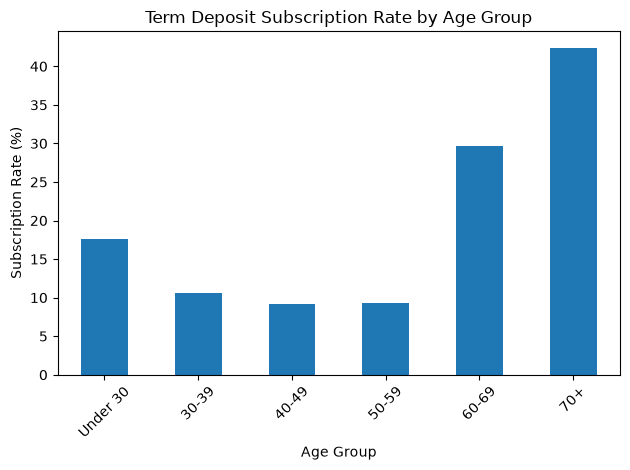

In [8]:
age_subscription.plot(kind="bar")

plt.title("Term Deposit Subscription Rate by Age Group")
plt.xlabel("Age Group")
plt.ylabel("Subscription Rate (%)")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

### Business Interpretation

Comparing age groups allows the bank to determine whether campaign response differs across stages of the customer lifecycle.

Age should not be interpreted independently, however. Differences between age groups may also reflect employment status, account balances, housing obligations, or other customer characteristics.